# IBM SpaceX Falcon 9 – Complete Capstone Project
**Student:** Titisha Doyel  
**Purpose:** Collect, clean, explore, visualize, map, query, and model SpaceX Falcon 9 launch data.

Run every cell from top to bottom using **Runtime → Run all**. Keep the outputs visible before downloading the executed notebook. This notebook uses public IBM Skills Network / SpaceX capstone datasets and documents the source URLs.

## 1. Install and import libraries

In [1]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn folium plotly dash sqlalchemy requests beautifulsoup4

In [2]:
import os, json, sqlite3, warnings, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
print("Libraries loaded successfully")

Libraries loaded successfully


## 2. Data collection – SpaceX API and web source
The following cells attempt to collect launch records from the public SpaceX API. If API access is unavailable, the notebook loads the IBM Skills Network capstone dataset as a reliable fallback.

In [3]:
api_url = "https://api.spacexdata.com/v4/launches/past"
api_records = []
try:
    response = requests.get(api_url, timeout=30)
    response.raise_for_status()
    api_records = response.json()
    print("SpaceX API records collected:", len(api_records))
except Exception as e:
    print("SpaceX API request unavailable:", repr(e))

SpaceX API request unavailable: HTTPError('522 Server Error: <none> for url: https://api.spacexdata.com/v4/launches/past')


In [15]:
wiki_url = "https://en.wikipedia.org/wiki/List_of_Falcon_9_and_Falcon_Heavy_launches"

wiki_tables = []

try:
    headers = {
        "User-Agent": "Mozilla/5.0 (compatible; StudentResearch/1.0)"
    }

    response = requests.get(
        wiki_url,
        headers=headers,
        timeout=30
    )

    response.raise_for_status()

    from io import StringIO
    wiki_tables = pd.read_html(StringIO(response.text))

    print("Tables retrieved:", len(wiki_tables))
    display(wiki_tables[0].head())

except Exception as e:
    print("Wikipedia access unavailable:", repr(e))

Tables retrieved: 19


,List of Falcon 9 and Falcon Heavy launches
0,2010–2019 · 2020–2022 · 2023 · 2024 · 2025 · 2...


## 3. Load the IBM capstone dataset
This dataset contains 90 Falcon 9 launch records with launch site, payload, orbit, outcome, and success-class information.

In [16]:
DATA_URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv"
FALLBACK_URL = "https://raw.githubusercontent.com/Abhigyan-RA/SpaceX-capstone/main/dataset_part_2.csv"
df = None
for url in [DATA_URL, FALLBACK_URL]:
    try:
        candidate = pd.read_csv(url)
        if len(candidate) > 0:
            df = candidate
            print("Loaded dataset from:", url)
            break
    except Exception as e:
        print("Could not load:", url, "|", str(e)[:180])
if df is None:
    raise RuntimeError("Dataset download failed. Check Colab internet access and rerun this cell.")
print("Shape:", df.shape)
display(df.head())
display(df.info())

Loaded dataset from: https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv
Shape: (90, 18)


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   FlightNumber    90 non-null     int64  
 1   Date            90 non-null     object 
 2   BoosterVersion  90 non-null     object 
 3   PayloadMass     90 non-null     float64
 4   Orbit           90 non-null     object 
 5   LaunchSite      90 non-null     object 
 6   Outcome         90 non-null     object 
 7   Flights         90 non-null     int64  
 8   GridFins        90 non-null     bool   
 9   Reused          90 non-null     bool   
 10  Legs            90 non-null     bool   
 11  LandingPad      64 non-null     object 
 12  Block           90 non-null     float64
 13  ReusedCount     90 non-null     int64  
 14  Serial          90 non-null     object 
 15  Longitude       90 non-null     float64
 16  Latitude        90 non-null     float64
 17  Class           90 non-null     int64

None

## 4. Data wrangling and quality checks

In [17]:
print("Missing values before cleaning:")
display(df.isna().sum().sort_values(ascending=False).head(15).to_frame("missing_count"))
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
if "PayloadMass" in df.columns:
    df["PayloadMass"] = pd.to_numeric(df["PayloadMass"], errors="coerce")
if "Class" not in df.columns:
    raise ValueError("Expected target column 'Class' is missing.")
df["Class"] = pd.to_numeric(df["Class"], errors="coerce")
df = df.dropna(subset=["Class"])
df["Class"] = df["Class"].astype(int)
print("Cleaned shape:", df.shape)
display(df.head())

Missing values before cleaning:


,missing_count
LandingPad,26
FlightNumber,0
Date,0
BoosterVersion,0
Orbit,0
PayloadMass,0
Outcome,0
Flights,0
GridFins,0
LaunchSite,0


Duplicate rows: 0
Cleaned shape: (90, 18)


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


## 5. Exploratory data analysis – outcome and launch sites

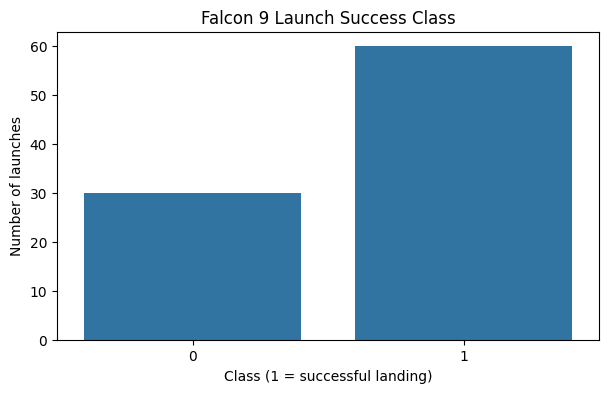

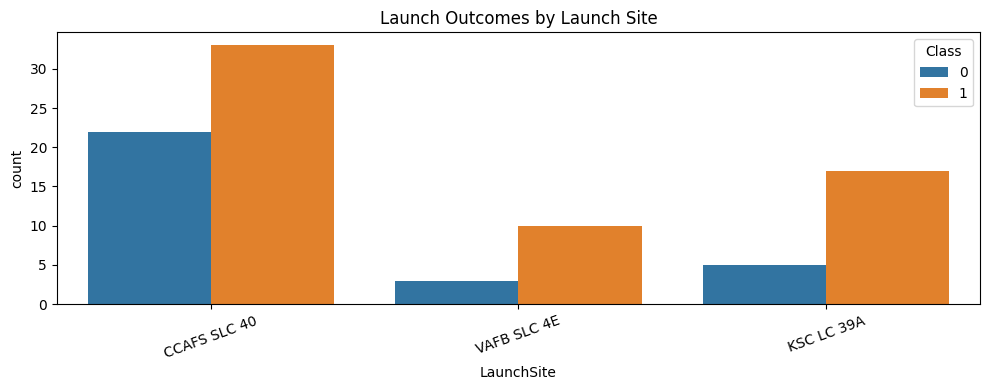

In [18]:
plt.figure(figsize=(7,4))
sns.countplot(data=df, x="Class")
plt.title("Falcon 9 Launch Success Class")
plt.xlabel("Class (1 = successful landing)")
plt.ylabel("Number of launches")
plt.show()
if "LaunchSite" in df:
    plt.figure(figsize=(10,4))
    sns.countplot(data=df, x="LaunchSite", hue="Class")
    plt.title("Launch Outcomes by Launch Site")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

## 6. EDA – payload, orbit, flight number, and yearly trend

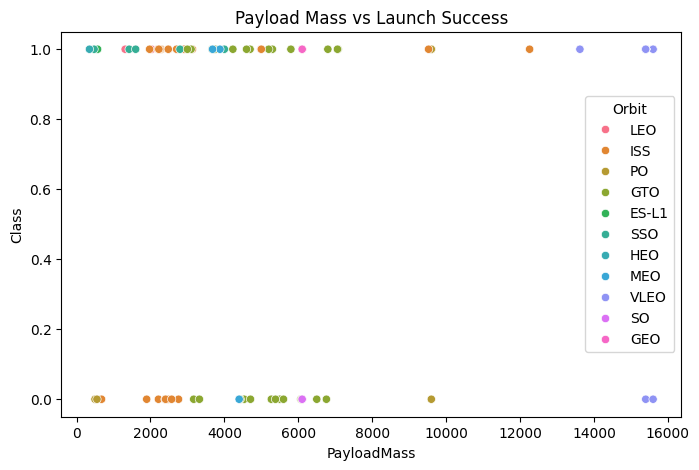

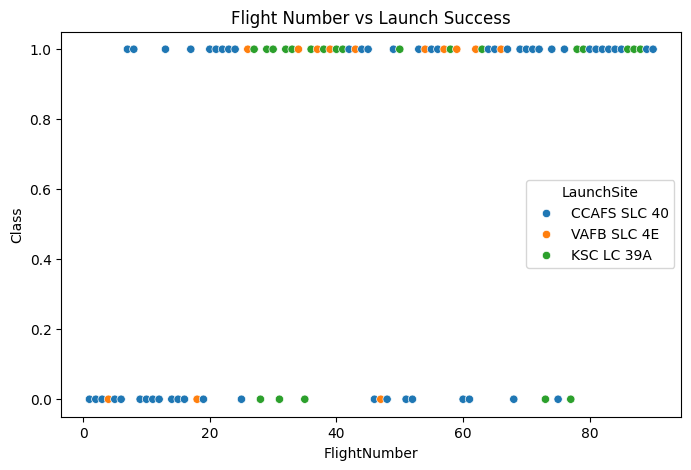

,Year,Class,SuccessRate
0,2010,0.000000,0.000000
1,2012,0.000000,0.000000
2,2013,0.000000,0.000000
3,2014,0.333333,33.333333
4,2015,0.333333,33.333333
5,2016,0.625000,62.500000
6,2017,0.833333,83.333333
7,2018,0.611111,61.111111
8,2019,0.900000,90.000000
9,2020,0.842105,84.210526


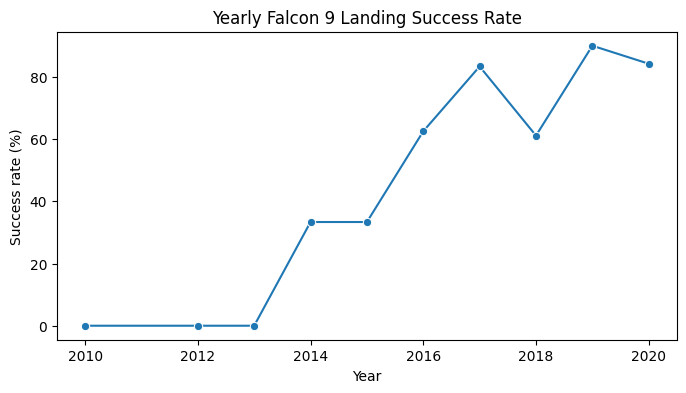

In [19]:
if {"PayloadMass","Class"}.issubset(df.columns):
    plt.figure(figsize=(8,5))
    sns.scatterplot(data=df, x="PayloadMass", y="Class", hue="Orbit" if "Orbit" in df else None)
    plt.title("Payload Mass vs Launch Success")
    plt.show()
if {"FlightNumber","Class"}.issubset(df.columns):
    plt.figure(figsize=(8,5))
    sns.scatterplot(data=df, x="FlightNumber", y="Class", hue="LaunchSite" if "LaunchSite" in df else None)
    plt.title("Flight Number vs Launch Success")
    plt.show()
if "Date" in df.columns:
    yearly = df.dropna(subset=["Date"]).assign(Year=lambda x: x["Date"].dt.year).groupby("Year", as_index=False)["Class"].mean()
    yearly["SuccessRate"] = yearly["Class"] * 100
    display(yearly)
    plt.figure(figsize=(8,4))
    sns.lineplot(data=yearly, x="Year", y="SuccessRate", marker="o")
    plt.title("Yearly Falcon 9 Landing Success Rate")
    plt.ylabel("Success rate (%)")
    plt.show()

## 7. SQL analysis using SQLite

In [20]:
conn = sqlite3.connect(":memory:")
df.to_sql("launches", conn, index=False, if_exists="replace")
queries = {
    "Launch count by site": "SELECT LaunchSite, COUNT(*) AS launches FROM launches GROUP BY LaunchSite ORDER BY launches DESC",
    "Success rate by site": "SELECT LaunchSite, COUNT(*) AS launches, ROUND(100.0*AVG(Class),2) AS success_rate_pct FROM launches GROUP BY LaunchSite ORDER BY success_rate_pct DESC",
    "Success rate by orbit": "SELECT Orbit, COUNT(*) AS launches, ROUND(100.0*AVG(Class),2) AS success_rate_pct FROM launches GROUP BY Orbit ORDER BY success_rate_pct DESC",
    "Payload summary": "SELECT Orbit, ROUND(AVG(PayloadMass),2) AS avg_payload_kg, MIN(PayloadMass) AS min_payload_kg, MAX(PayloadMass) AS max_payload_kg FROM launches GROUP BY Orbit ORDER BY avg_payload_kg DESC",
    "Top flight records": "SELECT FlightNumber, LaunchSite, Orbit, PayloadMass, Class FROM launches ORDER BY FlightNumber DESC LIMIT 10"
}
for title, query in queries.items():
    print("\n" + title)
    display(pd.read_sql_query(query, conn))


Launch count by site


,LaunchSite,launches
0,CCAFS SLC 40,55
1,KSC LC 39A,22
2,VAFB SLC 4E,13



Success rate by site


,LaunchSite,launches,success_rate_pct
0,KSC LC 39A,22,77.27
1,VAFB SLC 4E,13,76.92
2,CCAFS SLC 40,55,60.00



Success rate by orbit


,Orbit,launches,success_rate_pct
0,SSO,5,100.00
1,HEO,1,100.00
2,GEO,1,100.00
3,ES-L1,1,100.00
4,VLEO,14,85.71
5,LEO,7,71.43
6,PO,9,66.67
7,MEO,3,66.67
8,ISS,21,61.90
9,GTO,27,51.85



Payload summary


,Orbit,avg_payload_kg,min_payload_kg,max_payload_kg
0,VLEO,15315.71,13620.000000,15600.000000
1,PO,7583.67,500.000000,9600.000000
2,SO,6104.96,6104.959412,6104.959412
3,GEO,6104.96,6104.959412,6104.959412
4,GTO,5011.99,3000.000000,7076.000000
5,MEO,3987.00,3681.000000,4400.000000
6,LEO,3882.84,525.000000,6104.959412
7,ISS,3279.94,677.000000,12259.000000
8,SSO,2060.00,475.000000,4000.000000
9,ES-L1,570.00,570.000000,570.000000



Top flight records


,FlightNumber,LaunchSite,Orbit,PayloadMass,Class
0,90,CCAFS SLC 40,MEO,3681.000000,1
1,89,CCAFS SLC 40,VLEO,15400.000000,1
2,88,KSC LC 39A,VLEO,15400.000000,1
3,87,KSC LC 39A,VLEO,15400.000000,1
4,86,KSC LC 39A,VLEO,15400.000000,1
5,85,CCAFS SLC 40,SSO,1600.000000,1
6,84,CCAFS SLC 40,VLEO,15400.000000,1
7,83,CCAFS SLC 40,GEO,6104.959412,1
8,82,CCAFS SLC 40,MEO,3880.000000,1
9,81,CCAFS SLC 40,VLEO,15400.000000,1


## 8. Interactive visual analytics – Plotly

In [21]:
if {"PayloadMass","Class"}.issubset(df.columns):
    fig = px.scatter(df, x="PayloadMass", y="Class", color="Orbit" if "Orbit" in df else None,
                     hover_data=[c for c in ["FlightNumber","LaunchSite","Date"] if c in df],
                     title="Interactive: Payload Mass vs Landing Outcome")
    fig.show()
if "LaunchSite" in df:
    site_counts = df.groupby("LaunchSite", as_index=False).size()
    fig2 = px.bar(site_counts, x="LaunchSite", y="size", title="Launches by Site")
    fig2.show()

## 9. Folium map – launch sites and records

In [34]:
import folium

site_coords = {
    "CCAFS SLC 40": [28.561857, -80.577366],
    "KSC LC 39A": [28.608058, -80.603956],
    "VAFB SLC 4E": [34.632093, -120.610829]
}

m = folium.Map(
    location=[30, -95],
    zoom_start=4,
    tiles=None
)

for site, coords in site_coords.items():

    data = df[df["LaunchSite"] == site]

    folium.CircleMarker(
        location=coords,
        radius=9,
        color="red",
        fill=True,
        fill_color="blue",
        fill_opacity=0.8,
        tooltip=site,
        popup=f"{site} | Launches: {len(data)} | Successful: {data['Class'].sum()}"
    ).add_to(m)

m.fit_bounds(list(site_coords.values()))

display(m)

m.save("spacex_launch_sites_map.html")

print("Map created successfully")

Map created successfully


In [35]:
print("Total launch sites:", len(site_coords))

for site in site_coords:
    print(site, ":", len(df[df["LaunchSite"] == site]), "launches")

Total launch sites: 3
CCAFS SLC 40 : 55 launches
KSC LC 39A : 22 launches
VAFB SLC 4E : 13 launches


In [36]:
from math import radians, sin, cos, sqrt, atan2
from itertools import combinations

def distance_km(a, b):
    R = 6371
    lat1, lon1 = map(radians, a)
    lat2, lon2 = map(radians, b)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    x = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2
    return 2 * R * atan2(sqrt(x), sqrt(1-x))

for s1, s2 in combinations(site_coords, 2):
    d = distance_km(site_coords[s1], site_coords[s2])
    print(f"{s1} to {s2}: {d:.2f} km")

CCAFS SLC 40 to KSC LC 39A: 5.76 km
CCAFS SLC 40 to VAFB SLC 4E: 3825.87 km
KSC LC 39A to VAFB SLC 4E: 3821.64 km


In [37]:
import zipfile
import os

files = [
    "spacex_cleaned_data.csv",
    "model_comparison.csv",
    "sql_queries.txt",
    "spacex_launch_sites_map.html",
    "app.py",
    "dataset_part_2.csv"
]

with zipfile.ZipFile("SpaceX_Project_Evidence.zip", "w") as z:
    for file in files:
        if os.path.exists(file):
            z.write(file)

print("Project evidence ZIP created successfully!")

Project evidence ZIP created successfully!


In [38]:
from google.colab import files
files.download("SpaceX_Project_Evidence.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Predictive analysis – compare classification models

,Model,Accuracy
3,Gradient Boosting,0.888889
1,Decision Tree,0.833333
2,Random Forest,0.833333
0,Logistic Regression,0.777778


Best model: Gradient Boosting
              precision    recall  f1-score   support

           0       0.83      0.83      0.83         6
           1       0.92      0.92      0.92        12

    accuracy                           0.89        18
   macro avg       0.88      0.88      0.88        18
weighted avg       0.89      0.89      0.89        18



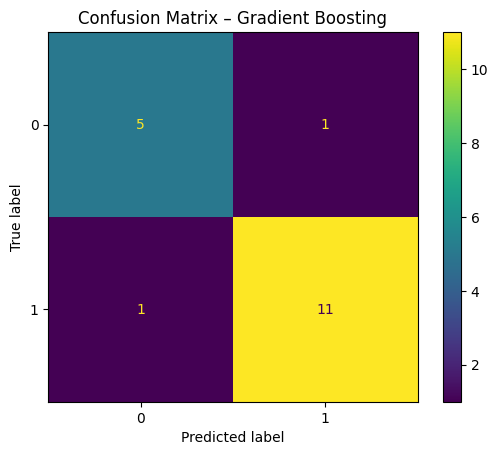

In [23]:
target = "Class"
candidate_features = [c for c in ["FlightNumber","PayloadMass","Orbit","LaunchSite","Flights","GridFins","Reused","Legs","Block","ReusedCount"] if c in df.columns]
model_df = df[candidate_features + [target]].copy()
X = model_df[candidate_features]
y = model_df[target]
numeric_features = X.select_dtypes(include=["number","bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]
numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numeric_pipe, numeric_features), ("cat", categorical_pipe, categorical_features)])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}
results = []
fitted = {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    score = accuracy_score(y_test, pred)
    results.append({"Model": name, "Accuracy": score})
    fitted[name] = pipe
results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
display(results_df)
best_name = results_df.iloc[0]["Model"]
best_model = fitted[best_name]
best_pred = best_model.predict(X_test)
print("Best model:", best_name)
print(classification_report(y_test, best_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred)
plt.title(f"Confusion Matrix – {best_name}")
plt.show()

## 11. Dash dashboard source code
This cell writes a runnable Dash application to `app.py`. In Colab, the dashboard can be launched with a public tunnel if your environment permits it; otherwise the interactive Plotly figures above provide notebook-based visual analytics evidence.

In [24]:
dash_source = r'''
import pandas as pd
import plotly.express as px
from dash import Dash, dcc, html
df = pd.read_csv("dataset_part_2.csv")
app = Dash(__name__)
app.layout = html.Div([
    html.H1("SpaceX Falcon 9 Launch Dashboard"),
    dcc.Graph(figure=px.pie(df, names="Class", title="Launch Success Distribution")),
    dcc.Graph(figure=px.scatter(df, x="PayloadMass", y="Class", color="LaunchSite",
                                hover_data=["FlightNumber"], title="Payload vs Landing Outcome")),
    dcc.Graph(figure=px.bar(df.groupby("LaunchSite", as_index=False).size(),
                            x="LaunchSite", y="size", title="Launches by Site"))
])
if __name__ == "__main__":
    app.run(debug=True, host="0.0.0.0", port=8050)
'''
with open("app.py", "w") as f:
    f.write(dash_source)
df.to_csv("dataset_part_2.csv", index=False)
print("Created app.py and dataset_part_2.csv")
print("To run locally: pip install dash plotly pandas && python app.py")

Created app.py and dataset_part_2.csv
To run locally: pip install dash plotly pandas && python app.py


## 12. Export evidence and project files

In [14]:
# Save reproducible analysis outputs
df.to_csv("spacex_cleaned_data.csv", index=False)
results_df.to_csv("model_comparison.csv", index=False)
with open("sql_queries.txt", "w") as f:
    for title, query in queries.items():
        f.write(title + "\n" + query + "\n\n")
print("Files created:")
for filename in ["spacex_cleaned_data.csv","model_comparison.csv","sql_queries.txt","spacex_launch_sites_map.html","app.py","dataset_part_2.csv"]:
    print(filename, os.path.getsize(filename), "bytes")

Files created:
spacex_cleaned_data.csv 11820 bytes
model_comparison.csv 157 bytes
sql_queries.txt 792 bytes
spacex_launch_sites_map.html 9369 bytes
app.py 723 bytes
dataset_part_2.csv 11820 bytes


## 13. Conclusion
This project demonstrates data collection, cleaning, exploratory analysis, SQL querying, interactive visualization, geospatial mapping, and supervised classification for Falcon 9 landing outcomes. Use the printed tables, rendered charts, map, model comparison, and confusion matrix as evidence in the final presentation.

**Important:** Do not claim API or web scraping succeeded if those cells show an error. Keep the actual outputs from your own Colab run. The Dash source is generated as `app.py`; it is not proof of a deployed/live dashboard unless you launch it and capture the running app.

In [26]:
!python app.py > dash.log 2>&1 &

In [27]:
from google.colab.output import eval_js
url = eval_js("google.colab.kernel.proxyPort(8050)")
print(url)

https://8050-m-s-usw1b7-3a0nq0abp7hs8-b.us-west1.prod.r.colab.dev
